# # Praktikum 1 — CNN Klasifikasi Cat vs Dog
# Modul asli memakai dataset Cat/Dog dari Google Drive. Dataset itu tidak dapat diunduh otomatis di lingkungan ini,
# sehingga dipakai **padanan**: kelas *cat* (indeks 3) dan *dog* (indeks 5) dari CIFAR-10 asli, di-resize ke 64x64
# sesuai target_size modul. 1000 citra latih + 200 citra uji per kelas.
#
# Generator: `ImageDataGenerator` (masih tersedia di Keras 2.15 walau deprecated) supaya alur `flow_from_directory`
# sama persis dengan modul.

In [1]:
import os
__file__ = os.path.abspath("conv_cat_dog.ipynb")

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing import image

tf.random.set_seed(42); np.random.seed(42)

BASE = Path(__file__).resolve().parent.parent
DATA = BASE / "data" / "cat_dog"
OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(parents=True, exist_ok=True)
print("data:", DATA, "| train cat:", len(list((DATA / "training/cat").glob("*.png"))))

data: C:\code\pemmes26\js14-convolutional-neural-network\data\cat_dog | train cat: 1000


# ## 1. Generator data
# rescale 1/255, target 64x64, batch 32, class_mode biner.

In [2]:
train_datagen = ImageDataGenerator(rescale=1. / 255, rotation_range=15,
                                   width_shift_range=0.1, height_shift_range=0.1,
                                   zoom_range=0.1, horizontal_flip=True)
test_datagen = ImageDataGenerator(rescale=1. / 255)

train_gen = train_datagen.flow_from_directory(
    DATA / "training", target_size=(64, 64), batch_size=32,
    class_mode="binary", shuffle=True, seed=42)
test_gen = test_datagen.flow_from_directory(
    DATA / "test", target_size=(64, 64), batch_size=32,
    class_mode="binary", shuffle=False)
print(train_gen.class_indices, train_gen.samples, test_gen.samples)

Found 2000 images belonging to 2 classes.


Found 387 images belonging to 2 classes.


{'cat': 0, 'dog': 1} 2000 387


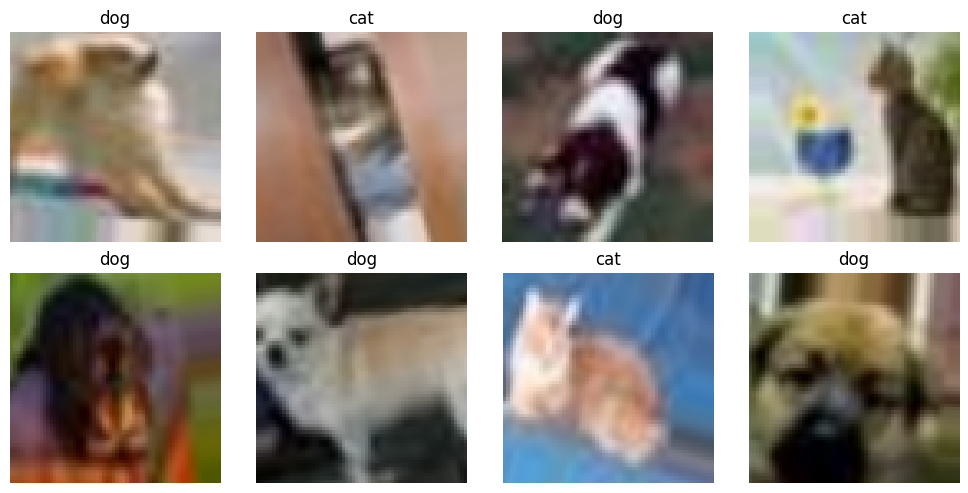

In [3]:
# contoh batch latih
xb, yb = next(iter(train_gen))
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, im, lb in zip(axes.ravel(), xb, yb):
    ax.imshow(im); ax.set_title("dog" if lb else "cat"); ax.axis("off")
plt.tight_layout(); plt.savefig(OUT / "contoh_batch.png", dpi=110); plt.show()

# ## 2. Arsitektur: 2 Conv + 2 Pool + Dense

In [4]:
model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(64, 64, 3)),
    MaxPooling2D(2, 2),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),
    Flatten(),
    Dropout(0.5),
    Dense(64, activation="relu"),
    Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 conv2d (Conv2D)             (None, 62, 62, 32)        896       


 max_pooling2d (MaxPooling2  (None, 31, 31, 32)        0         


 D)                                                              


... (7 outputs left out)

Total params: 411681 (1.57 MB)


Trainable params: 411681 (1.57 MB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


# ## 3. Pelatihan (15 epoch, 2000 citra latih + augmentasi, CPU)

In [5]:
history = model.fit(train_gen, epochs=15, validation_data=test_gen, verbose=2)

Epoch 1/15


63/63 - 11s - loss: 0.6960 - accuracy: 0.5125 - val_loss: 0.6890 - val_accuracy: 0.5607 - 11s/epoch - 173ms/step


Epoch 2/15


63/63 - 7s - loss: 0.6810 - accuracy: 0.5690 - val_loss: 0.6744 - val_accuracy: 0.5917 - 7s/epoch - 108ms/step


Epoch 3/15


63/63 - 7s - loss: 0.6754 - accuracy: 0.5850 - val_loss: 0.6686 - val_accuracy: 0.5969 - 7s/epoch - 109ms/step


... (20 outputs left out)

Epoch 14/15


63/63 - 7s - loss: 0.6233 - accuracy: 0.6510 - val_loss: 0.6311 - val_accuracy: 0.6460 - 7s/epoch - 117ms/step


Epoch 15/15


63/63 - 8s - loss: 0.6148 - accuracy: 0.6615 - val_loss: 0.6329 - val_accuracy: 0.6641 - 8s/epoch - 124ms/step


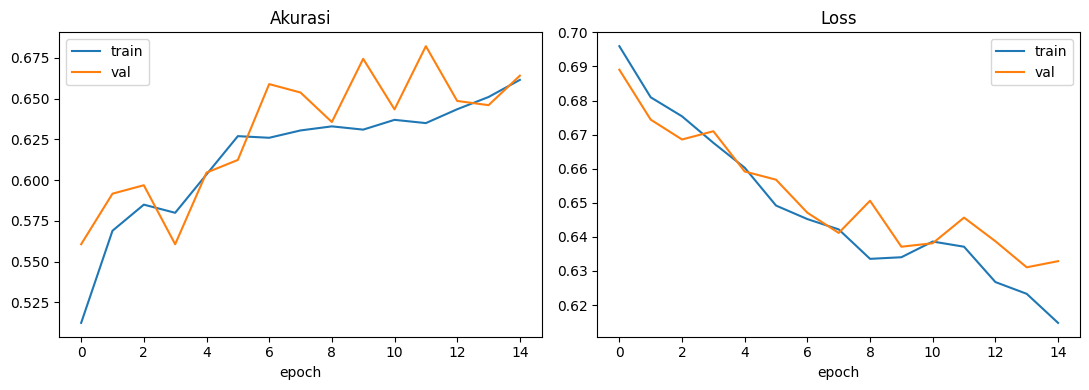

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Akurasi"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / "history.png", dpi=110); plt.show()

# ## 4. Evaluasi + prediksi satu citra

In [7]:
loss, acc = model.evaluate(test_gen, verbose=0)
print(f"test_loss={loss:.4f}  test_acc={acc:.4f}")
np.savetxt(OUT / "test_acc.csv", np.array([[loss, acc]]), delimiter=",", header="loss,acc", comments="")

test_loss=0.6329  test_acc=0.6641


file: cat_or_dog_1.jpg | p(dog) = 0.6117 | prediksi: dog | label asli: cat


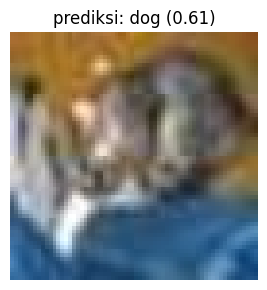

In [8]:
img_path = BASE / "data" / "single_prediction" / "cat_or_dog_1.jpg"
img = image.load_img(img_path, target_size=(64, 64))
arr = image.img_to_array(img) / 255.0
prob = float(model.predict(np.expand_dims(arr, 0), verbose=0)[0][0])
print("file:", img_path.name, "| p(dog) =", round(prob, 4),
      "| prediksi:", "dog" if prob > 0.5 else "cat", "| label asli: cat")

fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(img); ax.axis("off")
ax.set_title(f"prediksi: {'dog' if prob > 0.5 else 'cat'} ({prob:.2f})")
plt.tight_layout(); plt.savefig(OUT / "prediksi_satu_citra.png", dpi=110); plt.show()